In [229]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
import pickle as pkl
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

input_path = PROJECT_ROOT / "data" / "data_with_topics.pkl"

with open(input_path, "rb") as f:
    df = pkl.load(f)

df['moral_rating'] = pd.to_numeric(df['moral_rating'], errors='coerce')
df = df.dropna(subset=['moral_rating'])
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['year'] = df['date'].dt.year

PARTY_SV_NORMALIZE = {
    "Moderata samlingspartiet": "Moderaterna",
    "Folkpartiet liberalerna": "Liberalerna",
    "Folkpartiet": "Liberalerna",
    "Kristdemokratiska Samhällspartiet": "Kristdemokraterna",
    "Vänsterpartiet Kommunisterna": "Vänsterpartiet",
}

REMOVE_PARTIES = {"Utan partibeteckning", "no party"}

df.head()
len(df)

427014

In [230]:
# df["date"] = pd.to_datetime(df["date"])

# summer_recess = (
#     ((df["date"].dt.month == 6) & (df["date"].dt.day >= 17))
#     | (df["date"].dt.month == 7)
#     | ((df["date"].dt.month == 9) & (df["date"].dt.day <= 15))
#     | (df["date"].dt.month == 8)
#     | ((df["date"].dt.month == 9) & (df["date"].dt.day <= 15))
# )

# df = df.loc[~summer_recess].copy()

In [231]:
df.head()

,person_id,date,party_id,party_name,moral_rating,new_custom_id,topic_label,year
0,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,2,row_0,Foreign affairs and global trade,1996
1,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,i-F6Stwe8wVnSPa3BbgusszQ,Moderata samlingspartiet,4,row_1,"Law, order and justice",1996
2,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,2,row_2,Immigration and integration,1996
3,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,i-F6Stwe8wVnSPa3BbgusszQ,Moderata samlingspartiet,3,row_3,"Law, order and justice",1996
4,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,1,row_4,"Law, order and justice",1996


In [232]:
# only include from 1991 election onward
df = df[df['moral_rating'] != 0]
df =df[df['date'] >= pd.to_datetime("1991-09-15")]

In [233]:
stats = {}

In [234]:
stats['number of speeches'] = len(df)
df['party_name_norm'] = df['party_name'].replace(PARTY_SV_NORMALIZE)
print(len(df))
df = df[~df['party_name_norm'].isin(REMOVE_PARTIES)]
stats['number of valid speeches'] = len(df)

414891


In [235]:
stats

{'number of speeches': 414891, 'number of valid speeches': 395943}

In [236]:
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "DejaVu Serif"]

In [237]:

government_periods = {
    (pd.to_datetime("1991-10-03"), pd.to_datetime("1994-10-06")): [
        "Centerpartiet", "Liberalerna", "Moderaterna", "Kristdemokraterna"
    ],
    (pd.to_datetime("1994-10-06"), pd.to_datetime("1996-03-20")): [
        "Socialdemokraterna"
    ],
    (pd.to_datetime("1996-03-21"), pd.to_datetime("1998-09-19")): [
        "Socialdemokraterna"
    ],
    (pd.to_datetime("1998-09-20"), pd.to_datetime("2002-09-14")): [
        "Socialdemokraterna"
    ],
    (pd.to_datetime("2002-09-15"), pd.to_datetime("2006-10-04")): [
        "Socialdemokraterna"
    ],
    (pd.to_datetime("2006-10-05"), pd.to_datetime("2010-09-18")): [
        "Centerpartiet", "Liberalerna", "Moderaterna", "Kristdemokraterna"
    ],
    (pd.to_datetime("2010-09-19"), pd.to_datetime("2014-10-02")): [
        "Centerpartiet", "Liberalerna", "Moderaterna", "Kristdemokraterna"
    ],
    (pd.to_datetime("2014-10-03"), pd.to_datetime("2019-01-20")): [
        "Socialdemokraterna", "Miljöpartiet"
    ],
    (pd.to_datetime("2019-01-21"), pd.to_datetime("2021-11-29")): [
        "Socialdemokraterna", "Miljöpartiet"
    ],
    (pd.to_datetime("2021-11-30"), pd.to_datetime("2022-10-17")): [
        "Socialdemokraterna"
    ],
    (pd.to_datetime("2022-10-18"), pd.to_datetime("2026-01-01")): [
        "Liberalerna", "Kristdemokraterna", "Moderaterna"
    ],
}



In [238]:
def get_power_status(row):
    for (start_date, end_date), gov_parties in government_periods.items():
        if start_date <= row['date'] < end_date:
            if row['party_name_norm'] in gov_parties:
                return "in power"
    return "not in power"


In [239]:
df['power_status'] = df[['date', 'party_name_norm']].apply(get_power_status, axis=1)

In [240]:
df.head()

,person_id,date,party_id,party_name,moral_rating,new_custom_id,topic_label,year,party_name_norm,power_status
0,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,2,row_0,Foreign affairs and global trade,1996,Socialdemokraterna,in power
1,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,i-F6Stwe8wVnSPa3BbgusszQ,Moderata samlingspartiet,4,row_1,"Law, order and justice",1996,Moderaterna,not in power
2,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,2,row_2,Immigration and integration,1996,Socialdemokraterna,in power
3,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,i-F6Stwe8wVnSPa3BbgusszQ,Moderata samlingspartiet,3,row_3,"Law, order and justice",1996,Moderaterna,not in power
4,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,1,row_4,"Law, order and justice",1996,Socialdemokraterna,in power


In [241]:
# Topic distribution
topic_dist = (
    df["topic_label"]
    .value_counts(dropna=False)
    .rename_axis("Topic")
    .reset_index(name="Count")
)

topic_dist["Percentage"] = (
    100 * topic_dist["Count"] / topic_dist["Count"].sum()
).round(1)

topic_dist

,Topic,Count,Percentage
0,"Law, order and justice",75156,19.0
1,Foreign affairs and global trade,64273,16.2
2,Labor market and employment,63025,15.9
3,"Social welfare, housing and rights",49222,12.4
4,"Climate, environment and energy",41596,10.5
5,"Education, research and culture",31538,8.0
6,Immigration and integration,25279,6.4
7,Defense and military,21233,5.4
8,Health,12518,3.2
9,Infrastructure and agriculture,7342,1.9


In [242]:
latex_table = topic_dist.to_latex(
    index=False,
    caption="Topic distribution of parliamentary speeches",
    label="tab:topic_distribution",
    column_format="lrr",
    escape=True,
)

print(latex_table)

\begin{table}
\caption{Topic distribution of parliamentary speeches}
\label{tab:topic_distribution}
\begin{tabular}{lrr}
\toprule
Topic & Count & Percentage \\
\midrule
Law, order and justice & 75156 & 19.000000 \\
Foreign affairs and global trade & 64273 & 16.200000 \\
Labor market and employment & 63025 & 15.900000 \\
Social welfare, housing and rights & 49222 & 12.400000 \\
Climate, environment and energy & 41596 & 10.500000 \\
Education, research and culture & 31538 & 8.000000 \\
Immigration and integration & 25279 & 6.400000 \\
Defense and military & 21233 & 5.400000 \\
Health & 12518 & 3.200000 \\
Infrastructure and agriculture & 7342 & 1.900000 \\
Macroeconomics and trade & 4761 & 1.200000 \\
\bottomrule
\end{tabular}
\end{table}



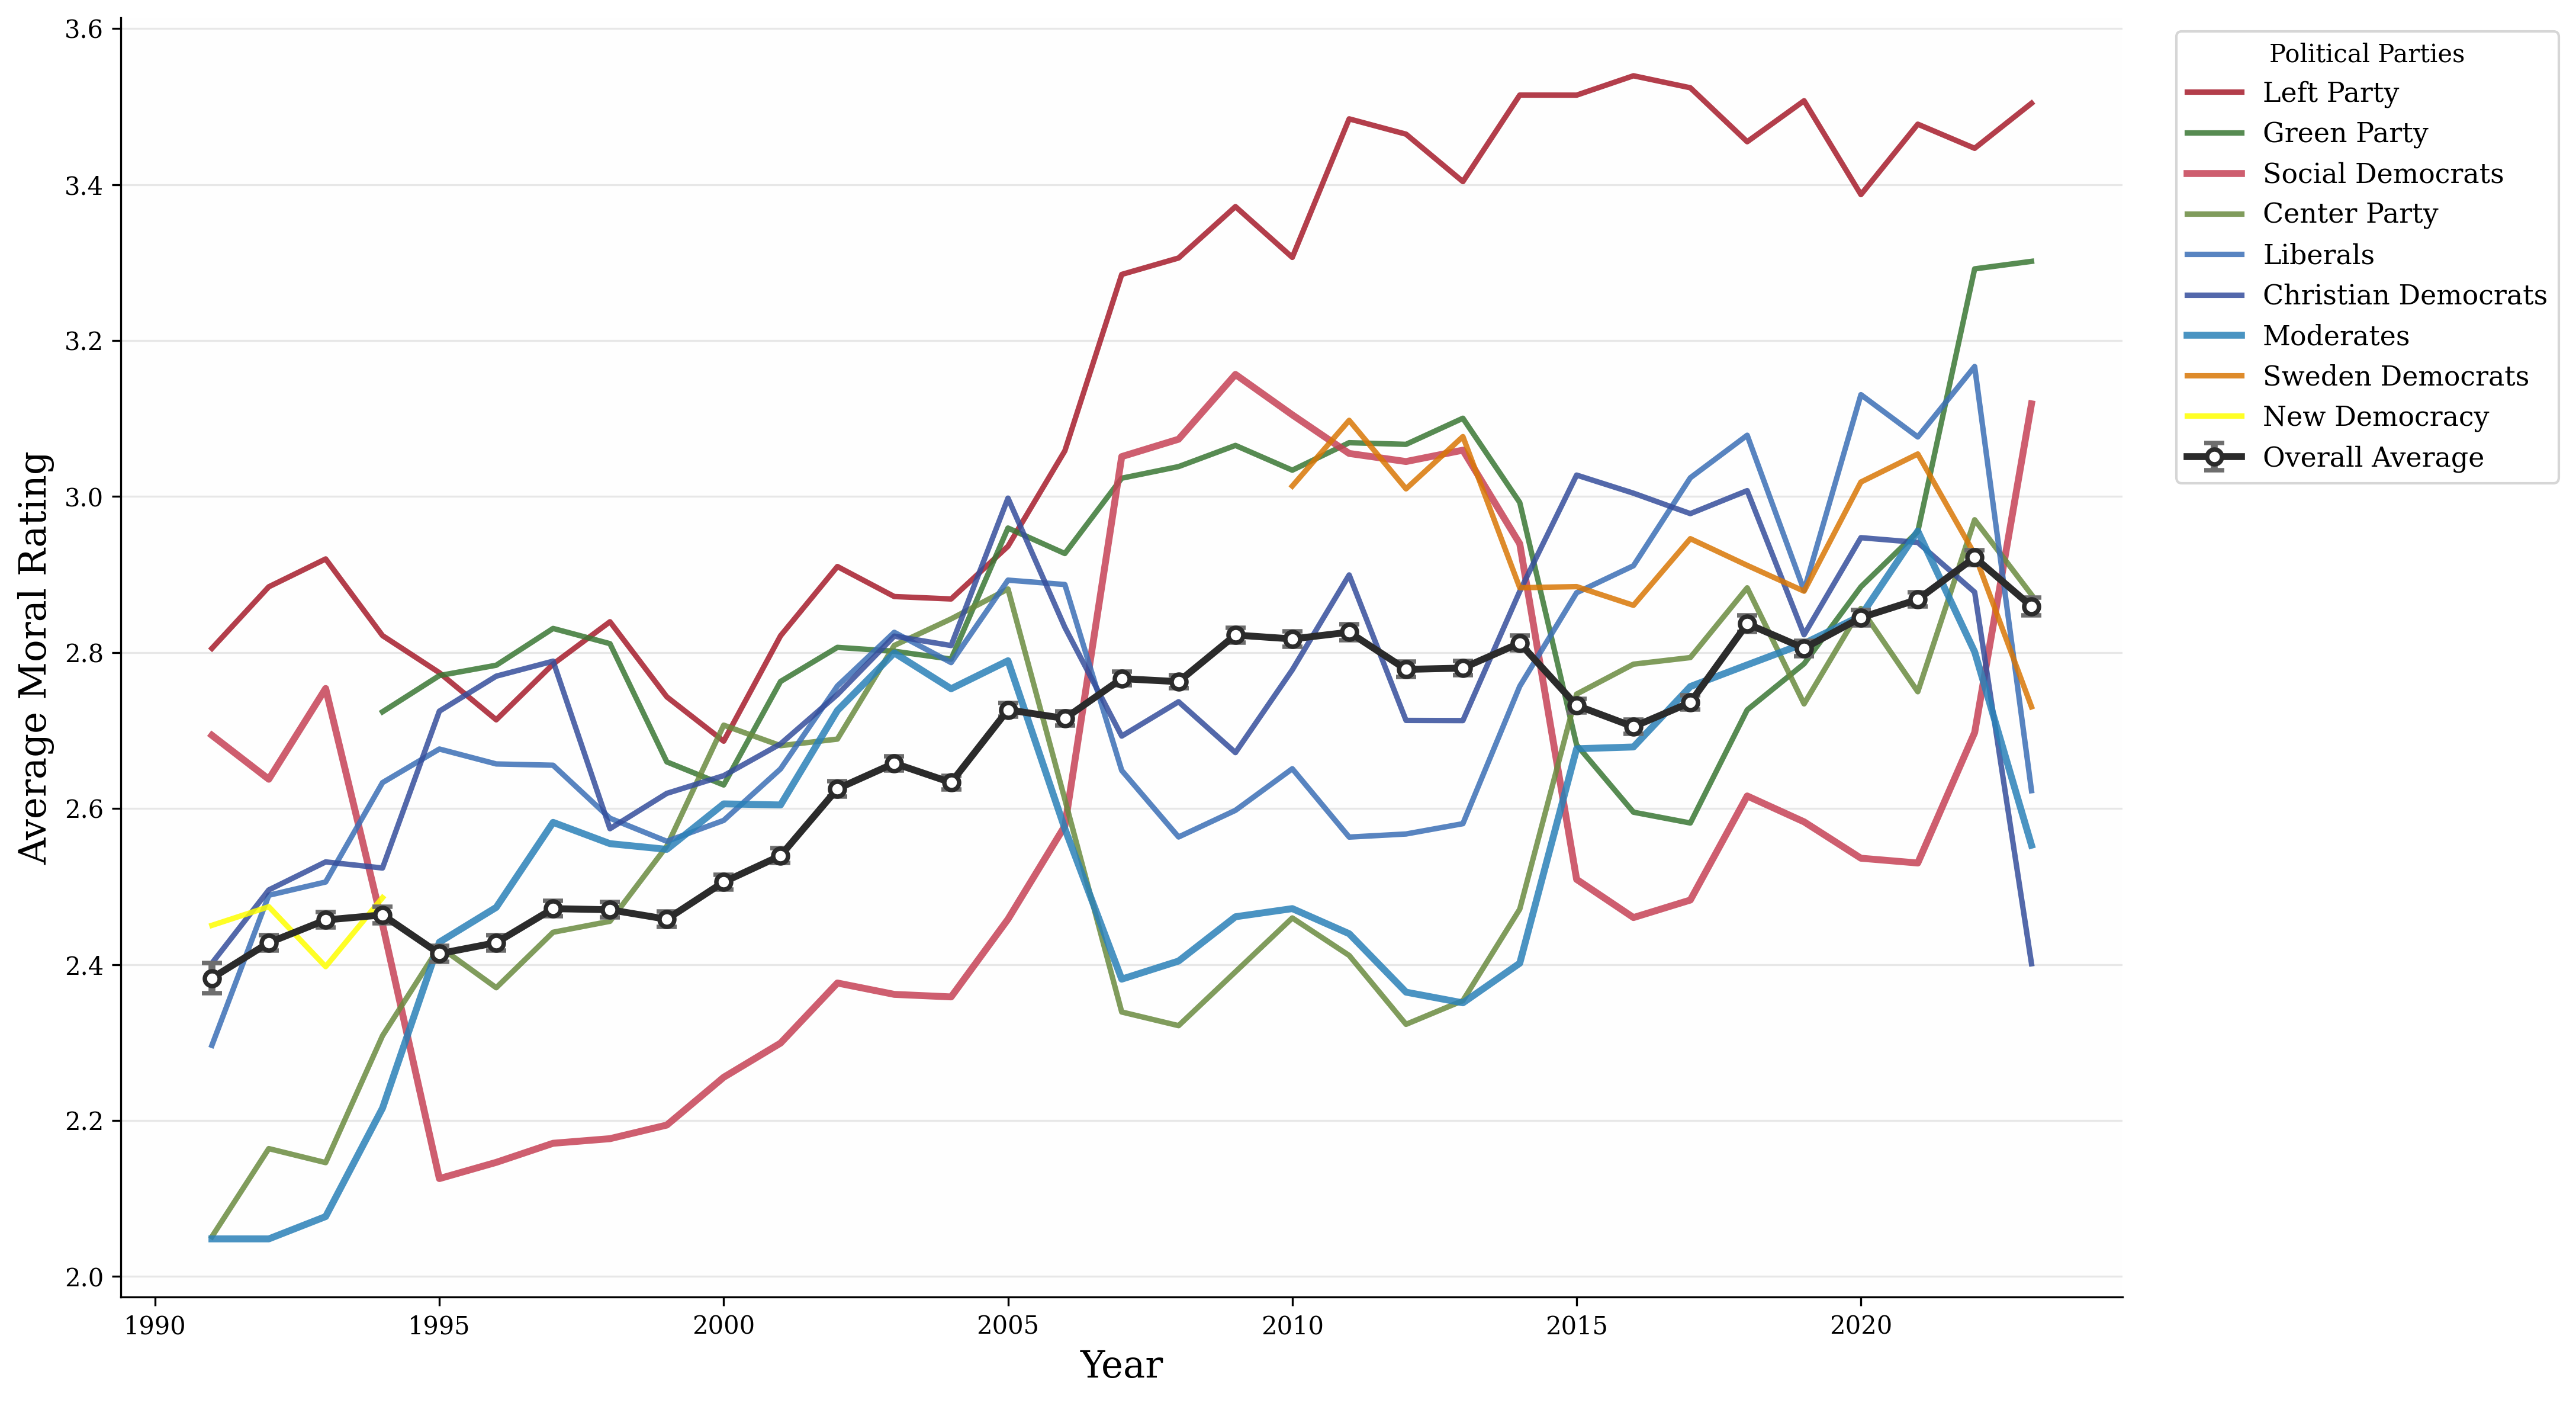

In [243]:
#plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman'], 'axes.linewidth': 1.5})

PARTY_EN = {"Vänsterpartiet": "Left Party", "Miljöpartiet": "Green Party", "Socialdemokraterna": "Social Democrats",
            "Centerpartiet": "Center Party", "Liberalerna": "Liberals", "Kristdemokraterna": "Christian Democrats",
            "Moderaterna": "Moderates", "Sverigedemokraterna": "Sweden Democrats", "Ny demokrati": "New Democracy"}
PARTY_ORDER = ["Left Party", "Green Party", "Social Democrats", "Center Party", "Liberals", "Christian Democrats", "Moderates", "Sweden Democrats"]
PARTY_COLORS = {"Left Party": '#A61C2B', "Green Party": '#3A7734', "Social Democrats": '#C64256', "Center Party": '#6A8B3F',
                "Liberals": '#3B6FB6', "Christian Democrats": '#354E9C', "Moderates": '#2A81B8', "Sweden Democrats": '#D97706', "New Democracy": '#ffff00'}

df_viz = df.copy()
df_viz['party_en'] = df_viz['party_name_norm'].map(PARTY_EN).fillna(df_viz['party_name_norm'])
party_means = df_viz.groupby(['year', 'party_en'])['moral_rating'].mean().unstack()
party_order = PARTY_ORDER + [p for p in party_means.columns if p not in PARTY_ORDER]
party_means = party_means.reindex(columns=party_order)
mean_ratings = df_viz.groupby('year')['moral_rating'].mean()
std_error = df_viz.groupby('year')['moral_rating'].std() / np.sqrt(df_viz.groupby('year').size())

fig, ax = plt.subplots(figsize=(16, 8), dpi=300)
ax.set_facecolor('#FEFEFE')
ax.grid(axis='y', linestyle='-', alpha=0.15, linewidth=0.8, color='#666')

for party in party_means.columns:
    lw = 2.8 if party in ["Social Democrats", "Moderates"] else 2.2
    ax.plot(party_means.index, party_means[party], lw=lw, color=PARTY_COLORS.get(party, '#999'), alpha=0.85, label=party)

ax.errorbar(
    mean_ratings.index,
    mean_ratings.values,
    yerr=std_error,
    fmt='o-',
    color='#2B2B2B',
    ecolor='#6E6E6E',
    capsize=4,
    lw=2.8,
    markersize=6,
    capthick=1.4,
    markerfacecolor='white',
    markeredgewidth=1.8,
    label='Overall Average',
    zorder=10
)

ax.set_xlabel('Year', fontsize=15)
ax.set_ylabel('Average Moral Rating', fontsize=15)
#ax.set_title("Average moral rating by year and party", pad=20, fontsize=16)
for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
ax.legend(title='Political Parties', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=11, frameon=True)
plt.tight_layout()
plt.subplots_adjust(right=0.75)
out_path = PROJECT_ROOT / "results" / "figures" / "parties.jpg"
plt.savefig(out_path)
plt.show()



In [256]:
ELECTIONS = {
    1991: "1991-09-15",
    1994: "1994-09-18",
    1998: "1998-09-20",
    2002: "2002-09-15",
    2006: "2006-09-17",
    2010: "2010-09-19",
    2014: "2014-09-14",
    2018: "2018-09-09",
    2022: "2022-09-11",
    2026: "2026-09-13"
}

# ELECTIONS = {
#     1991: "1991-06-17",
#     1994: "1994-06-17",
#     1998: "1998-06-17",
#     2002: "2002-06-17",
#     2006: "2006-06-17",
#     2010: "2010-06-17",
#     2014: "2014-06-17",
#     2018: "2018-06-17",
#     2022: "2022-06-17",
#     2026: "2026-06-17"
# }

/local/slurmtmp.3967014/ipykernel_2057319/1787383452.py:60: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


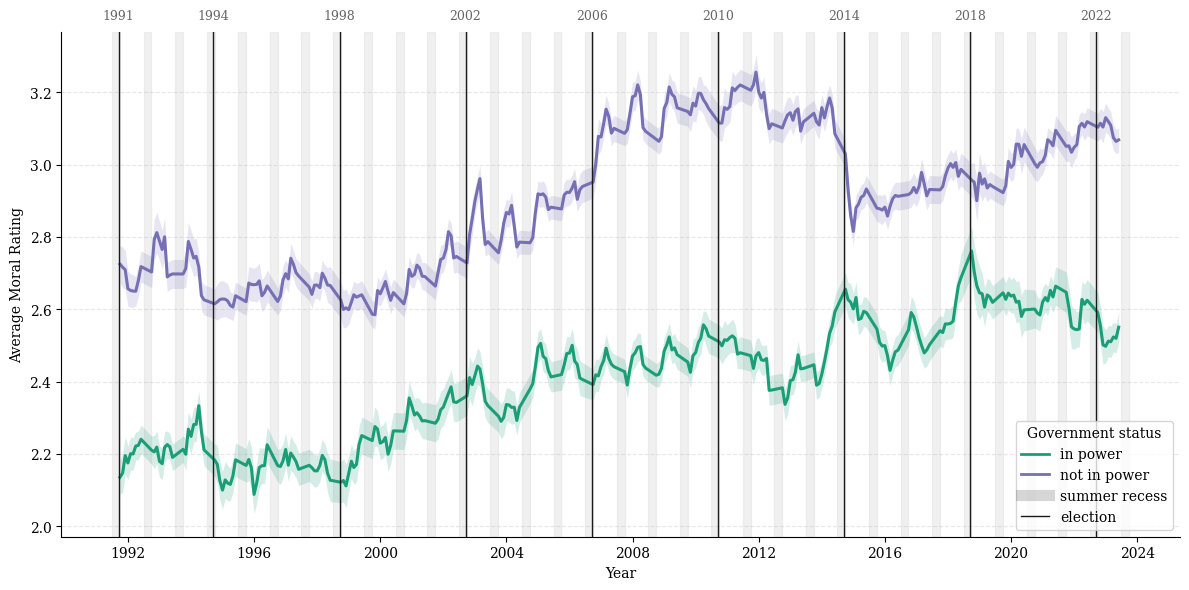

In [257]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.transforms as mtransforms


df_plot = df.copy()

# Dates
df_plot["date"] = pd.to_datetime(df_plot["date"], errors="coerce")

# Exclude summer recess months (July–September)
df_plot = df_plot[~df_plot["date"].dt.month.isin([7, 8, 9])]

df_plot = df_plot[df_plot["power_status"].notna()]
df_plot["moral_rating"] = pd.to_numeric(df_plot["moral_rating"], errors="coerce")
df_plot = df_plot.dropna(subset=["date", "moral_rating"])

df_plot["year_month"] = df_plot["date"].dt.to_period("M")
df_plot["power_status"] = np.where(
    df_plot["power_status"] == "supporting",
    "not in power",
    df_plot["power_status"]
)

summary = (
    df_plot
    .groupby(["year_month", "power_status"])["moral_rating"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
    .sort_values("year_month")
)

summary["se"] = summary["std"] / np.sqrt(summary["n"])
summary["month_ts"] = summary["year_month"].dt.to_timestamp()
summary["month_idx"] = (
    summary["year_month"].dt.year * 12 + summary["year_month"].dt.month
)

election_month_idx = (
    pd.to_datetime(list(ELECTIONS.values()))
    .year * 12
    + pd.to_datetime(list(ELECTIONS.values())).month
)

ELECTION_WINDOW = 2  # months

summary["election_break"] = summary["month_idx"].apply(
    lambda m: any(abs(em - m )< ELECTION_WINDOW for em in election_month_idx)
)


SMOOTH_WINDOW = 5  # months

summary = (
    summary
    .sort_values("month_idx")
    .groupby("power_status", group_keys=False)
    .apply(
        lambda d: d.assign(
            mean_smooth=d["mean"].rolling(
                SMOOTH_WINDOW, center=True, min_periods=1
            ).mean(),
            se_smooth=d["se"].rolling(
                SMOOTH_WINDOW, center=True, min_periods=1
            ).mean()
        )
    )
)


status_colors = {
    "in power": "#1b9e77",
    "not in power": "#7570b3",
    "supporting": "#d95f02"
}


fig, ax = plt.subplots(figsize=(12, 6))

for status, data in summary.groupby("power_status"):
    data = data.sort_values("month_idx")
    color = status_colors.get(status, "black")

    gaps = (
    data["month_idx"].diff().gt(6)
    )
    #data["election_break"] |
    #data["election_break"].shift(fill_value=False)
    #)
    
    segments = gaps.cumsum()


    for _, seg in data.groupby(segments):
        # Uncertainty band
        ax.fill_between(
            seg["month_ts"],
            seg["mean_smooth"] - seg["se_smooth"],
            seg["mean_smooth"] + seg["se_smooth"],
            color=color,
            alpha=0.18,
            linewidth=0
        )

        # Smoothed line
        ax.plot(
            seg["month_ts"],
            seg["mean_smooth"],
            lw=2.2,
            color=color
        )

# -------------------------
# Elections
# -------------------------



ELECTIONS_ = {
    1991: "1991-09-15",
    1994: "1994-09-18",
    1998: "1998-09-20",
    2002: "2002-09-15",
    2006: "2006-09-17",
    2010: "2010-09-19",
    2014: "2014-09-14",
    2018: "2018-09-09",
    2022: "2022-09-11",
    #2026: "2026-09-13"
}
trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)

for year, date_str in ELECTIONS_.items():
    election_date = pd.to_datetime(date_str)

    ax.axvline(
        election_date,
        linestyle="-",
        lw=1,
        color="0.1",
        alpha=1,
        zorder=3
    )

    ax.text(
        election_date,
        1.02,
        str(year),
        transform=trans,
        ha="center",
        va="bottom",
        fontsize=9,
        color="0.4"
    )


years = summary["month_ts"].dt.year.unique()

for year in years:
    ax.axvspan(
        pd.to_datetime(f"{year}-07-01"),
        pd.to_datetime(f"{year}-09-30"),
        color="0.9",
        alpha=0.6,
        zorder=0
    )


legend_elements = [
    Line2D([0], [0], color=color, lw=2, label=status)
    for status, color in status_colors.items()
    if status in summary["power_status"].unique()
]

legend_elements.append(
    Line2D([0], [0], color="0.2", lw=8, alpha=0.2, label="summer recess")
)

legend_elements.append(
    Line2D([0], [0], color="0.1", lw=1, linestyle="-", label="election")
)

ax.legend(handles=legend_elements, title="Government status")

#ax.set_title("Average moral rating by month and government status", pad=20)
ax.set_xlabel("Year")
ax.set_ylabel("Average Moral Rating")
#ax.set_xlim(1991, 2023)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
out_path = PROJECT_ROOT / "results" / "figures" / "rolling.jpg"
plt.savefig(out_path)
plt.show()



In [258]:
def days_to_next_election(date):
    if pd.isna(date):
        return np.nan
    
    future_deltas = (election_dates - date).days
    future_deltas = future_deltas[future_deltas >= 0]

    return future_deltas.min() if len(future_deltas) > 0 else np.nan


In [259]:
election_dates = pd.to_datetime(list(ELECTIONS.values()))

df["days_to_next_election"] = df["date"].apply(days_to_next_election)


In [260]:
def get_gov_status_dummy(row):
    if row['power_status'] == 'in power':
        return 1
    else:
        return 0

df['gov_status'] = df.apply(get_gov_status_dummy, axis = 1)
print(df['gov_status'].unique())

[1 0]


In [261]:
df.head()

,person_id,date,party_id,party_name,moral_rating,new_custom_id,topic_label,year,party_name_norm,power_status,days_to_next_election,gov_status
0,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,2,row_0,Foreign affairs and global trade,1996,Socialdemokraterna,in power,940,1
1,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,i-F6Stwe8wVnSPa3BbgusszQ,Moderata samlingspartiet,4,row_1,"Law, order and justice",1996,Moderaterna,not in power,940,0
2,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,2,row_2,Immigration and integration,1996,Socialdemokraterna,in power,940,1
3,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,i-F6Stwe8wVnSPa3BbgusszQ,Moderata samlingspartiet,3,row_3,"Law, order and justice",1996,Moderaterna,not in power,940,0
4,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,i-VS8ddgxigwL5TceKtXGApS,Socialdemokraterna,1,row_4,"Law, order and justice",1996,Socialdemokraterna,in power,940,1


In [262]:
election_periods = election_dates.to_period('M')

In [263]:
FIG_DIR = PROJECT_ROOT / "results" / "figures"

# Speech-level regression

In [264]:
df_speech = df[[
    "moral_rating",
    "gov_status",
    "days_to_next_election",
    "person_id",
    "party_name_norm",
    "date",
    "topic_label"
    ]]

df_speech = df_speech.rename(columns = {'party_name_norm' : 'party'})
df_speech['election_term'] = (
    election_periods
        .searchsorted(pd.PeriodIndex(df_speech["date"], freq="M"), side='right')
        - 1
)

df_speech['covid_year'] = df_speech["date"].dt.year.isin([2020]).astype(int)
df_speech['refugee_crisis'] = df_speech["date"].dt.year.isin([2015]).astype(int)


df_speech.head()

,moral_rating,gov_status,days_to_next_election,person_id,party,date,topic_label,election_term,covid_year,refugee_crisis
0,2,1,940,i-4CwyNH4xXJhZj5wdBAzmSY,Socialdemokraterna,1996-02-23,Foreign affairs and global trade,1,0,0
1,4,0,940,i-F8qdE2eedz12PwFanq3ahv,Moderaterna,1996-02-23,"Law, order and justice",1,0,0
2,2,1,940,i-4CwyNH4xXJhZj5wdBAzmSY,Socialdemokraterna,1996-02-23,Immigration and integration,1,0,0
3,3,0,940,i-F8qdE2eedz12PwFanq3ahv,Moderaterna,1996-02-23,"Law, order and justice",1,0,0
4,1,1,940,i-4CwyNH4xXJhZj5wdBAzmSY,Socialdemokraterna,1996-02-23,"Law, order and justice",1,0,0


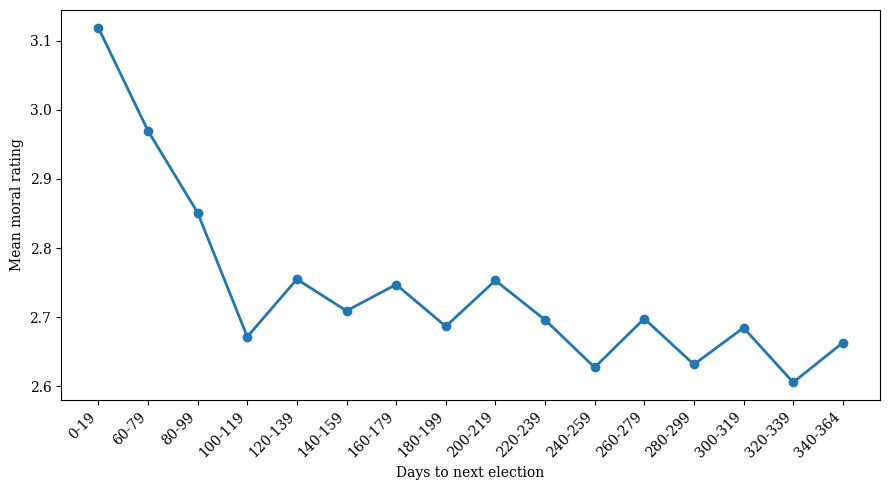

In [265]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df_speech.reset_index().copy()

# Ensure numeric
df_plot["moral_rating"] = pd.to_numeric(df_plot["moral_rating"], errors="coerce")
df_plot["days_to_next_election"] = pd.to_numeric(
    df_plot["days_to_next_election"],
    errors="coerce"
)

# Keep only observations up to 2 years before election
df_plot = df_plot[
    (df_plot["days_to_next_election"] >= 0) &
    (df_plot["days_to_next_election"] <= 365)
].copy()

df_plot = df_plot.dropna(subset=["moral_rating", "days_to_next_election"])

# Equal-length bins: 90-day intervals up to 730 days
bins = list(range(0, 345, 20)) + [365]

labels = [
    f"{bins[i]}-{bins[i+1] - 1}"
    for i in range(len(bins) - 1)
]

df_plot["election_bin_equal_length"] = pd.cut(
    df_plot["days_to_next_election"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=False
)

# Summarize by bin
bin_summary = (
    df_plot
    .groupby("election_bin_equal_length", observed=True)
    .agg(
        mean_moral_rating=("moral_rating", "mean"),
        n=("moral_rating", "size"),
        mean_days=("days_to_next_election", "mean")
    )
    .reset_index()
)

# Add n to labels
bin_summary["label"] = (
    bin_summary["election_bin_equal_length"].astype(str)
)

# Plot
plt.figure(figsize=(9, 5))

plt.plot(
    bin_summary["label"],
    bin_summary["mean_moral_rating"],
    marker="o",
    linewidth=2
)

plt.xlabel("Days to next election")
plt.ylabel("Mean moral rating")
#plt.title("Moral rating by election proximity, up to two years before election")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "equal_length_bins_two_years_before_election.jpg",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [266]:
df_speech = df_speech.set_index(["person_id", "date"])

df_speech["months_to_election"] = df_speech["days_to_next_election"] / 30.44

df_speech["log_months_to_election"] = np.log(df_speech["months_to_election"] + 1)

In [267]:
from linearmodels.panel import PanelOLS
from stargazer.stargazer import Stargazer

# without gov status and with party * election interactions

mod0 = PanelOLS.from_formula(
    "moral_rating ~ log_months_to_election + EntityEffects + C(election_term)",
    data=df_speech
).fit(cov_type='clustered', cluster_entity=True, cluster_time=True)



mod1 = PanelOLS.from_formula(
    "moral_rating ~ gov_status + log_months_to_election + EntityEffects + C(election_term)",
    data=df_speech
).fit(cov_type='clustered', cluster_entity=True, cluster_time=True)


mod2 = PanelOLS.from_formula(
    "moral_rating ~ gov_status + log_months_to_election + EntityEffects + C(topic_label) + C(election_term)",
    data=df_speech
).fit(cov_type='clustered', cluster_entity=True, cluster_time=True)

mod3 = PanelOLS.from_formula(
    "moral_rating ~ gov_status*log_months_to_election + EntityEffects + C(topic_label) + C(election_term)",
    data=df_speech
).fit(cov_type='clustered', cluster_entity=True, cluster_time=True)



stargazer = Stargazer([mod0, mod1, mod2, mod3])

latex_table = stargazer.render_latex()

print(latex_table)


\begin{table}[!htbp] \centering
\begin{tabular}{@{\extracolsep{5pt}}lcccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{4}{c}{\textit{Dependent variable: moral_rating}} \
\cr \cline{2-5}
\\[-1.8ex] & (1) & (2) & (3) & (4) \\
\hline \\[-1.8ex]
 C(election_term)[0] & 2.745$^{***}$ & 2.958$^{***}$ & & \\
& (0.054) & (0.041) & & \\
 C(election_term)[1] & 2.685$^{***}$ & 2.829$^{***}$ & & \\
& (0.037) & (0.033) & & \\
 C(election_term)[2] & 2.797$^{***}$ & 2.935$^{***}$ & & \\
& (0.036) & (0.032) & & \\
 C(election_term)[3] & 2.876$^{***}$ & 3.015$^{***}$ & & \\
& (0.033) & (0.031) & & \\
 C(election_term)[4] & 2.922$^{***}$ & 3.152$^{***}$ & & \\
& (0.038) & (0.031) & & \\
 C(election_term)[5] & 2.865$^{***}$ & 3.117$^{***}$ & & \\
& (0.036) & (0.030) & & \\
 C(election_term)[6] & 2.788$^{***}$ & 3.001$^{***}$ & & \\
& (0.043) & (0.034) & & \\
 C(election_term)[7] & 2.801$^{***}$ & 3.008$^{***}$ & & \\
& (0.046) & (0.036) & & \\
 C(election_term)[8] & 2.808$^{***}$ & 3.044$^{***}$ & &

In [268]:
print(mod2.rsquared_overall)

0.08373977496756813


In [269]:
mod2.summary

Dep. Variable:,moral_rating,R-squared:,0.0369
Estimator:,PanelOLS,R-squared (Between):,0.2424
No. Observations:,395943,R-squared (Within):,0.0369
Date:,"Fri, Oct 23 2026",R-squared (Overall):,0.0837
Time:,13:19:26,Log-likelihood,-5.502e+05
Cov. Estimator:,Clustered,,
,,F-statistic:,756.12
Entities:,1707,P-value,0.0000
Avg Obs:,231.95,Distribution:,"F(20,394216)"
Min Obs:,1.0000,,
Max Obs:,2753.0,F-statistic (robust):,3.154e+04


In [270]:
# with event controls

mod3 = PanelOLS.from_formula(
    "moral_rating ~ gov_status + log_months_to_election + EntityEffects + C(topic_label) + C(election_term) + covid_year + refugee_crisis",
    data=df_speech
).fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
mod3.summary

mod4 = PanelOLS.from_formula(
    "moral_rating ~ gov_status*log_months_to_election + EntityEffects + C(topic_label) + C(election_term) + covid_year + refugee_crisis",
    data=df_speech
).fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
mod4.summary

Dep. Variable:,moral_rating,R-squared:,0.0370
Estimator:,PanelOLS,R-squared (Between):,0.2419
No. Observations:,395943,R-squared (Within):,0.0370
Date:,"Fri, Oct 23 2026",R-squared (Overall):,0.0837
Time:,13:19:35,Log-likelihood,-5.502e+05
Cov. Estimator:,Clustered,,
,,F-statistic:,658.56
Entities:,1707,P-value,0.0000
Avg Obs:,231.95,Distribution:,"F(23,394213)"
Min Obs:,1.0000,,
Max Obs:,2753.0,F-statistic (robust):,2.787e+04


In [271]:
stargazer = Stargazer([mod3, mod4])

latex_table = stargazer.render_latex()

print(latex_table)

\begin{table}[!htbp] \centering
\begin{tabular}{@{\extracolsep{5pt}}lcc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{2}{c}{\textit{Dependent variable: moral_rating}} \
\cr \cline{2-3}
\\[-1.8ex] & (1) & (2) \\
\hline \\[-1.8ex]
 C(election_term)[T.1] & -0.119$^{***}$ & -0.119$^{***}$ \\
& (0.039) & (0.039) \\
 C(election_term)[T.2] & -0.011$^{}$ & -0.012$^{}$ \\
& (0.042) & (0.042) \\
 C(election_term)[T.3] & 0.074$^{*}$ & 0.074$^{*}$ \\
& (0.044) & (0.044) \\
 C(election_term)[T.4] & 0.214$^{***}$ & 0.213$^{***}$ \\
& (0.048) & (0.048) \\
 C(election_term)[T.5] & 0.184$^{***}$ & 0.183$^{***}$ \\
& (0.050) & (0.050) \\
 C(election_term)[T.6] & 0.062$^{}$ & 0.062$^{}$ \\
& (0.058) & (0.058) \\
 C(election_term)[T.7] & 0.094$^{}$ & 0.092$^{}$ \\
& (0.058) & (0.058) \\
 C(election_term)[T.8] & 0.138$^{**}$ & 0.137$^{**}$ \\
& (0.064) & (0.064) \\
 C(topic_label)[Climate, environment and energy] & 2.863$^{***}$ & 2.887$^{***}$ \\
& (0.044) & (0.045) \\
 C(topic_label)[Defense and mil

In [272]:
import statsmodels.formula.api as smf

df_speech_no_index = df_speech.reset_index()

person_codes = df_speech_no_index["person_id"].astype("category").cat.codes
day_codes = df_speech_no_index["date"].astype("category").cat.codes
speech_groups = np.column_stack((person_codes, day_codes))
# print(speech_groups.shape)
# print(len(df_speech_no_index))


mod0 = smf.ols(
    "moral_rating ~   C(party, Treatment(reference='Socialdemokraterna')) + log_months_to_election + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})


mod1 = smf.ols(
    "moral_rating ~  gov_status +  C(party, Treatment(reference='Socialdemokraterna')) + log_months_to_election + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})


mod2 = smf.ols(
    "moral_rating ~  gov_status +  C(party, Treatment(reference='Socialdemokraterna')) + log_months_to_election +  C(topic_label)  + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})

mod3 = smf.ols(
    "moral_rating ~  gov_status *log_months_to_election + C(party, Treatment(reference='Socialdemokraterna')) +  C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})

mod4 = smf.ols(
    "moral_rating ~  gov_status *log_months_to_election * C(party, Treatment(reference='Socialdemokraterna')) +  C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})

print(mod4.summary())

stargazer = Stargazer([mod0, mod1, mod2, mod3])

latex_table = stargazer.render_latex()

print(latex_table)


                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.106
Model:                            OLS   Adj. R-squared:                  0.106
Method:                 Least Squares   F-statistic:                     70.62
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:19:49   Log-Likelihood:            -5.6821e+05
No. Observations:              395943   AIC:                         1.137e+06
Df Residuals:                  395895   BIC:                         1.137e+06
Df Model:                          47                                         
Covariance Type:              cluster                                         
                                                                                                                   coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------

/home/emma_b/.local/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 53, but rank is 47
  warnings.warn('covariance of constraints does not have full '


In [273]:
mod4 = smf.ols(
    "moral_rating ~  log_months_to_election + C(party, Treatment(reference='Socialdemokraterna')) +  C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})


mod5 = smf.ols(
    "moral_rating ~  gov_status + log_months_to_election + C(party, Treatment(reference='Socialdemokraterna')) +  C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})

mod6 = smf.ols(
    "moral_rating ~  gov_status  + log_months_to_election * C(party, Treatment(reference='Socialdemokraterna')) +  C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})



#print(mod4.summary())

stargazer = Stargazer([mod4, mod5, mod6])

latex_table = stargazer.render_latex()



print(latex_table)

\begin{table}[!htbp] \centering
\begin{tabular}{@{\extracolsep{5pt}}lccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{3}{c}{\textit{Dependent variable: moral_rating}} \
\cr \cline{2-4}
\\[-1.8ex] & (1) & (2) & (3) \\
\hline \\[-1.8ex]
 C(election_term)[T.1] & -0.022$^{}$ & -0.101$^{***}$ & -0.101$^{***}$ \\
& (0.048) & (0.038) & (0.038) \\
 C(election_term)[T.2] & 0.035$^{}$ & -0.053$^{}$ & -0.053$^{}$ \\
& (0.050) & (0.041) & (0.041) \\
 C(election_term)[T.3] & 0.189$^{***}$ & 0.103$^{**}$ & 0.103$^{**}$ \\
& (0.048) & (0.040) & (0.040) \\
 C(election_term)[T.4] & 0.310$^{***}$ & 0.298$^{***}$ & 0.297$^{***}$ \\
& (0.051) & (0.040) & (0.040) \\
 C(election_term)[T.5] & 0.315$^{***}$ & 0.310$^{***}$ & 0.310$^{***}$ \\
& (0.051) & (0.042) & (0.042) \\
 C(election_term)[T.6] & 0.261$^{***}$ & 0.226$^{***}$ & 0.226$^{***}$ \\
& (0.050) & (0.043) & (0.043) \\
 C(election_term)[T.7] & 0.377$^{***}$ & 0.326$^{***}$ & 0.326$^{***}$ \\
& (0.049) & (0.041) & (0.041) \\
 C(election_term)[T

In [274]:
df_speech_no_index = df_speech.reset_index()

person_codes = df_speech_no_index["person_id"].astype("category").cat.codes
day_codes = df_speech_no_index["date"].astype("category").cat.codes
speech_groups = np.column_stack((person_codes, day_codes))
print(speech_groups.shape)
print(len(df_speech_no_index))


mod2 = smf.ols(
    "moral_rating ~  gov_status * log_months_to_election  + C(party, Treatment(reference='Socialdemokraterna')) + C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})
print(mod2.summary())

(395943, 2)
395943
                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.105
Model:                            OLS   Adj. R-squared:                  0.105
Method:                 Least Squares   F-statistic:                     111.2
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:20:02   Log-Likelihood:            -5.6839e+05
No. Observations:              395943   AIC:                         1.137e+06
Df Residuals:                  395913   BIC:                         1.137e+06
Df Model:                          29                                         
Covariance Type:              cluster                                         
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------

In [275]:
mod3 = smf.ols(
    "moral_rating ~  gov_status +  C(party, Treatment(reference='Socialdemokraterna'))*log_months_to_election + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})
print(mod3.summary())

                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                  0.084
Method:                 Least Squares   F-statistic:                     38.51
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.88e-150
Time:                        13:20:04   Log-Likelihood:            -5.7301e+05
No. Observations:              395943   AIC:                         1.146e+06
Df Residuals:                  395916   BIC:                         1.146e+06
Df Model:                          26                                         
Covariance Type:              cluster                                         
                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------

In [276]:
mod4 = smf.ols(
    "moral_rating ~  gov_status +  C(party, Treatment(reference='Socialdemokraterna'))*log_months_to_election + C(topic_label) + C(election_term)",
    data=df_speech_no_index
).fit(cov_type="cluster",
    cov_kwds={"groups":speech_groups})
print(mod4.summary())

                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.105
Model:                            OLS   Adj. R-squared:                  0.105
Method:                 Least Squares   F-statistic:                     90.32
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:20:08   Log-Likelihood:            -5.6836e+05
No. Observations:              395943   AIC:                         1.137e+06
Df Residuals:                  395906   BIC:                         1.137e+06
Df Model:                          36                                         
Covariance Type:              cluster                                         
                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------

Law, order and justice


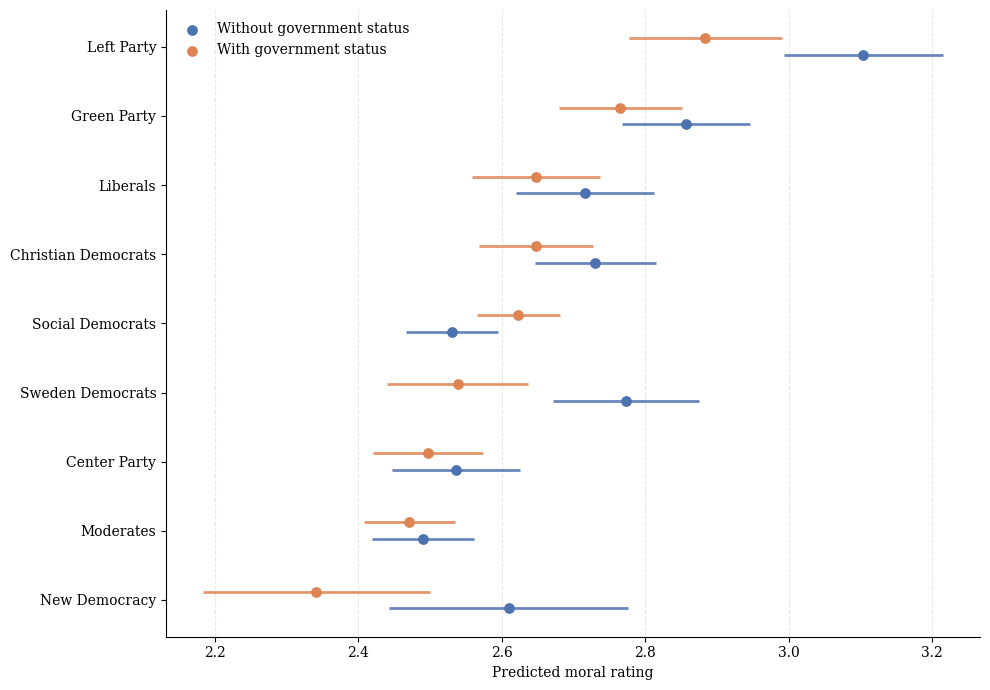

In [277]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Reference values
gov_ref = df_speech_no_index["gov_status"].mean()
election_term_ref = df_speech_no_index["election_term"].mode()[0]
log_months_ref = df_speech_no_index["log_months_to_election"].mean()
topic_ref = df_speech_no_index["topic_label"].mode()[0]
print(topic_ref)

parties = df_speech_no_index["party"].dropna().unique()

# Prediction data for model 1: without gov_status
pred_df = pd.DataFrame({
    "party": parties,
    "election_term": election_term_ref,
    "log_months_to_election": log_months_ref,
    "topic_label": topic_ref
})

# Prediction data for model 2: with gov_status
pred_df_2 = pd.DataFrame({
    "party": parties,
    "gov_status": gov_ref,
    "election_term": election_term_ref,
    "log_months_to_election": log_months_ref,
    "topic_label": topic_ref
})

# Model 1: without government status
model = smf.ols(
    """
    moral_rating ~ C(party, Treatment(reference='Socialdemokraterna'))
    + C(election_term)
    + C(topic_label)
    + log_months_to_election
    """,
    data=df_speech_no_index
).fit(
    cov_type="cluster",
    cov_kwds={"groups": speech_groups}
)

# Model 2: with government status
model2 = smf.ols(
    """
    moral_rating ~ C(party, Treatment(reference='Socialdemokraterna'))
    + C(election_term)
    + C(topic_label)
    + gov_status
    + log_months_to_election
    """,
    data=df_speech_no_index
).fit(
    cov_type="cluster",
    cov_kwds={"groups": speech_groups}
)

# Predictions for model 1
pred_summary = model.get_prediction(pred_df).summary_frame(alpha=0.05)

pred_df["pred"] = pred_summary["mean"].values
pred_df["ci_low"] = pred_summary["mean_ci_lower"].values
pred_df["ci_high"] = pred_summary["mean_ci_upper"].values
pred_df["model"] = "Without government status"

# Predictions for model 2
pred_summary_2 = model2.get_prediction(pred_df_2).summary_frame(alpha=0.05)

pred_df_2["pred"] = pred_summary_2["mean"].values
pred_df_2["ci_low"] = pred_summary_2["mean_ci_lower"].values
pred_df_2["ci_high"] = pred_summary_2["mean_ci_upper"].values
pred_df_2["model"] = "With government status"

# Combine
pred_all = pd.concat([pred_df, pred_df_2], ignore_index=True)

# English party names
pred_all["party_en"] = pred_all["party"].map(PARTY_EN).fillna(pred_all["party"])

# Sort parties by model 1 predictions
party_order = (
    pred_all[pred_all["model"] == "With government status"]
    .sort_values("pred")["party_en"]
    .tolist()
)

pred_all["party_en"] = pd.Categorical(
    pred_all["party_en"],
    categories=party_order,
    ordered=True
)

pred_all = pred_all.sort_values("party_en").copy()

# Numeric y positions
party_to_y = {party: i for i, party in enumerate(party_order)}
pred_all["y"] = pred_all["party_en"].map(party_to_y).astype(float)

# Swapped visual order:
# With government status appears above / first in legend
model_order = [
    "Without government status",
    "With government status"
]

offsets = {
    "Without government status": -0.12,
    "With government status": 0.12
}

colors = {
    "With government status": "#DD8452",
    "Without government status": "#4C72B0"
}

pred_all["y_offset"] = pred_all["y"] + pred_all["model"].map(offsets)

# Plot
fig, ax = plt.subplots(figsize=(10, 7))

for model_name in model_order:
    data = pred_all[pred_all["model"] == model_name]

    ax.hlines(
        y=data["y_offset"],
        xmin=data["ci_low"],
        xmax=data["ci_high"],
        color=colors[model_name],
        alpha=0.85,
        linewidth=2,
        label=None
    )

    ax.scatter(
        data["pred"],
        data["y_offset"],
        color=colors[model_name],
        s=45,
        label=model_name,
        zorder=3
    )

# Axis formatting
ax.set_yticks(range(len(party_order)))
ax.set_yticklabels(party_order)

ax.set_xlabel("Predicted moral rating")
ax.set_ylabel("")
ax.legend(frameon=False, loc="best")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "predicted_speech_level_two_models.jpg",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Event study

In [278]:
df_speech_no_index.head()

,person_id,date,moral_rating,gov_status,days_to_next_election,party,topic_label,election_term,covid_year,refugee_crisis,months_to_election,log_months_to_election
0,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992
1,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,4,0,940,Moderaterna,"Law, order and justice",1,0,0,30.88042,3.461992
2,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Immigration and integration,1,0,0,30.88042,3.461992
3,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,3,0,940,Moderaterna,"Law, order and justice",1,0,0,30.88042,3.461992
4,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,1,1,940,Socialdemokraterna,"Law, order and justice",1,0,0,30.88042,3.461992


In [279]:
# Put periods in chronological order
periods = sorted(
    [
        {
            "start": start,
            "end": end,
            "government_parties": set(parties)
        }
        for (start, end), parties in government_periods.items()
    ],
    key=lambda x: x["start"]
)

# All parties appearing in the government-period dictionary
all_parties = sorted(
    set().union(*(p["government_parties"] for p in periods))
)

transitions = []

for previous, current in zip(periods[:-1], periods[1:]):

    transition_date = current["start"]

    previous_gov = previous["government_parties"]
    current_gov = current["government_parties"]

    for party in all_parties:

        was_government = party in previous_gov
        is_government = party in current_gov

        # Only retain actual status changes
        if was_government != is_government:

            direction = (
                "gov_to_opp"
                if was_government and not is_government
                else "opp_to_gov"
            )

            transitions.append({
                "party": party,
                "transition_date": transition_date,
                "from_status": (
                    "government" if was_government else "opposition"
                ),
                "to_status": (
                    "government" if is_government else "opposition"
                ),
                "direction": direction
            })

transitions_df = pd.DataFrame(transitions)

transitions_df.head()

,party,transition_date,from_status,to_status,direction
0,Centerpartiet,1994-10-06,government,opposition,gov_to_opp
1,Kristdemokraterna,1994-10-06,government,opposition,gov_to_opp
2,Liberalerna,1994-10-06,government,opposition,gov_to_opp
3,Moderaterna,1994-10-06,government,opposition,gov_to_opp
4,Socialdemokraterna,1994-10-06,opposition,government,opp_to_gov


In [280]:
df_event = df_speech_no_index.merge(
    transitions_df,
    on="party",
    how="inner"
)

df_event["event_days"] = (
    df_event["date"] - df_event["transition_date"]
).dt.days

df_event["event_month"] = df_event["event_days"] / 30.44

df_event["month_of_year"] = pd.to_datetime(
    df_event["date"]
).dt.month

In [281]:
df_event.head()

,person_id,date,moral_rating,gov_status,days_to_next_election,party,topic_label,election_term,covid_year,refugee_crisis,months_to_election,log_months_to_election,transition_date,from_status,to_status,direction,event_days,event_month,month_of_year
0,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992,1994-10-06,opposition,government,opp_to_gov,505,16.590013,2
1,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992,2006-10-05,government,opposition,gov_to_opp,-3877,-127.365309,2
2,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992,2014-10-03,opposition,government,opp_to_gov,-6797,-223.291721,2
3,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992,2022-10-18,government,opposition,gov_to_opp,-9734,-319.776610,2
4,i-F8qdE2eedz12PwFanq3ahv,1996-02-23,4,0,940,Moderaterna,"Law, order and justice",1,0,0,30.88042,3.461992,1994-10-06,government,opposition,gov_to_opp,505,16.590013,2


In [282]:
df_event = df_event[
    df_event["event_month"].between(-24, 24)
].copy()

In [283]:
df_event['party'].unique()

array(['Socialdemokraterna', 'Moderaterna', 'Centerpartiet',
       'Kristdemokraterna', 'Liberalerna', 'Miljöpartiet'], dtype=object)

In [284]:
df_govopp = df_event[
    df_event["direction"] == "gov_to_opp"
].copy()

In [285]:
#create bins

df_govopp["event_bin"] = pd.cut(
    df_govopp["event_month"],
    bins=[-24, -18, -12, -6, 0, 6, 12, 18, 24],
    labels=[
        "24_to_18_before",
        "18_to_12_before",
        "12_to_6_before",
        "6_to_0_before",
        "0_to_6_after",
        "6_to_12_after",
        "12_to_18_after",
        "18_to_24_after"
    ],
    right=False,
    include_lowest=True
)

In [286]:
# set index again
df_govopp = df_govopp.set_index(["person_id", "date"])


In [287]:
# add linear time trend

df_govopp["time_trend"] = (
    df_govopp.index.get_level_values("date")
    - df_govopp.index.get_level_values("date").min()
).days / 365.25

In [288]:
#df_govopp["time_trend"].head(50)

In [289]:
event_dummies = pd.get_dummies(
    df_govopp["event_bin"],
    prefix="event",
    dtype=float
)

#event_dummies = event_dummies.drop(
#    columns="event_3_to_0_before"
#)

df_govopp = pd.concat(
    [df_govopp, event_dummies],
    axis=1
)

In [290]:
pd.crosstab(
    df_govopp["event_bin"],
    df_govopp["election_term"]
)

election_term,0,1,3,4,5,6,7,8
event_bin,,,,,,,,
24_to_18_before,3967,0,4012,0,3434,0,3636,0
18_to_12_before,2489,0,2216,0,2424,0,2171,0
12_to_6_before,3628,0,3509,0,4583,0,3383,0
6_to_0_before,2144,4,1679,2,1877,3,1610,35
0_to_6_after,0,2626,0,2223,0,3083,555,1730
6_to_12_after,0,1685,0,1392,0,2184,125,957
12_to_18_after,0,2474,0,2610,0,3211,0,775
18_to_24_after,0,1416,0,1609,0,2142,0,113


In [291]:
mod_event = PanelOLS.from_formula(
    """
    moral_rating ~ 1
    + C(event_bin, Treatment(reference='6_to_0_before'))
    + EntityEffects
    + C(topic_label)
    """,
    data=df_govopp
).fit(
    cov_type="clustered",
    cluster_entity=True,
    cluster_time=True
)
mod_event.summary

Dep. Variable:,moral_rating,R-squared:,0.0319
Estimator:,PanelOLS,R-squared (Between):,0.1518
No. Observations:,77716,R-squared (Within):,0.0319
Date:,"Fri, Oct 23 2026",R-squared (Overall):,0.0553
Time:,13:20:15,Log-likelihood,-1.063e+05
Cov. Estimator:,Clustered,,
,,F-statistic:,148.73
Entities:,864,P-value,0.0000
Avg Obs:,89.949,Distribution:,"F(17,76835)"
Min Obs:,1.0000,,
Max Obs:,797.00,F-statistic (robust):,35.767


In [292]:
mp_bin_means = (
    df_govopp
    .groupby(["person_id", "event_bin"], observed=True)["moral_rating"]
    .mean()
    .unstack()
)

# Difference from the reference period for each MP
within_diffs = mp_bin_means.sub(
    mp_bin_means["6_to_0_before"],
    axis=0
)

# Average within-MP difference across MPs
within_diffs.mean()

event_bin
24_to_18_before   -0.042911
18_to_12_before   -0.075482
12_to_6_before    -0.091977
6_to_0_before      0.000000
0_to_6_after       0.201974
6_to_12_after      0.283276
12_to_18_after     0.243582
18_to_24_after     0.261793
dtype: float64

In [293]:
# Integer month relative to transition
df_govopp["event_month_bin"] = np.floor(df_govopp["event_month"]).astype(int)

# Keep e.g. -12 to +11 months
df_govopp = df_govopp[
    df_govopp["event_month_bin"].between(-12, 11)
].copy()
mp_month_means = (
    df_govopp
    .groupby(["person_id", "event_month_bin"], observed=True)["moral_rating"]
    .mean()
    .unstack()
)
within_diffs_monthly = mp_month_means.sub(
    mp_month_means[-1],
    axis=0
)

within_diffs_monthly.mean()

event_month_bin
-12    0.445373
-11    0.308700
-10    0.294211
-9     0.220460
-8     0.442219
-7     0.098914
-6     0.318978
-5     0.246400
-4     1.196429
-3    -0.773652
-2     0.426667
-1     0.000000
 0     0.489310
 1     0.303950
 2     0.620962
 3     0.812910
 4     0.660368
 5     0.404222
 6     0.913492
 7     0.051961
 8     1.072222
 9     0.061905
 10    0.666667
 11    1.087500
dtype: float64

In [294]:
monthly_counts = (
    df_govopp
    .assign(
        person_id=df_govopp.index.get_level_values("person_id")
    )
    .groupby("event_month_bin")
    .agg(
        n_speeches=("moral_rating", "size"),
        n_mps=("person_id", "nunique")
    )
)

monthly_counts

,n_speeches,n_mps
event_month_bin,,
-12,2554,315
-11,2886,338
-10,2344,321
-9,1805,228
-8,2501,318
-7,3013,376
-6,2461,361
-5,2561,367
-4,2037,284


In [295]:
df_govopp["event_month_round"] = df_govopp["event_month"].round()

df_govopp.groupby("event_month_round")["moral_rating"].mean()

event_month_round
-12.0    2.349198
-11.0    2.363212
-10.0    2.439593
-9.0     2.413651
-8.0     2.526710
-7.0     2.470386
-6.0     2.513779
-5.0     2.481402
-4.0     2.486556
-3.0     2.498667
-2.0     2.713043
-1.0     2.896552
-0.0     2.671515
 1.0     2.733193
 2.0     2.818251
 3.0     3.009913
 4.0     2.849029
 5.0     2.850774
 6.0     2.850086
 7.0     2.846887
 8.0     2.829926
 9.0     3.006369
 10.0    3.135802
 11.0    2.964392
 12.0    2.889273
Name: moral_rating, dtype: float64

In [296]:
# Switch direction

df_oppgov = df_event[
    df_event["direction"] == "opp_to_gov"
].copy()
df_oppgov.head()

,person_id,date,moral_rating,gov_status,days_to_next_election,party,topic_label,election_term,covid_year,refugee_crisis,months_to_election,log_months_to_election,transition_date,from_status,to_status,direction,event_days,event_month,month_of_year
0,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992,1994-10-06,opposition,government,opp_to_gov,505,16.590013,2
8,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,Immigration and integration,1,0,0,30.88042,3.461992,1994-10-06,opposition,government,opp_to_gov,505,16.590013,2
16,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,1,1,940,Socialdemokraterna,"Law, order and justice",1,0,0,30.88042,3.461992,1994-10-06,opposition,government,opp_to_gov,505,16.590013,2
24,i-4CwyNH4xXJhZj5wdBAzmSY,1996-02-23,2,1,940,Socialdemokraterna,"Law, order and justice",1,0,0,30.88042,3.461992,1994-10-06,opposition,government,opp_to_gov,505,16.590013,2
28,i-4qJ1WSYreoe9MGDFPCwZKy,1996-02-23,4,1,940,Socialdemokraterna,Foreign affairs and global trade,1,0,0,30.88042,3.461992,1994-10-06,opposition,government,opp_to_gov,505,16.590013,2


In [297]:
#create bins

df_oppgov["event_bin"] = pd.cut(
    df_oppgov["event_month"],
    bins=[-24, -18, -12, -6, 0, 6, 12, 18, 24],
    labels=[
        "24_to_18_before",
        "18_to_12_before",
        "12_to_6_before",
        "6_to_0_before",
        "0_to_6_after",
        "6_to_12_after",
        "12_to_18_after",
        "18_to_24_after"
    ],
    right=False,
    include_lowest=True
)

In [298]:
# set index again
df_oppgov = df_oppgov.set_index(["person_id", "date"])


In [299]:
# add linear time trend

df_oppgov["time_trend"] = (
    df_oppgov.index.get_level_values("date")
    - df_oppgov.index.get_level_values("date").min()
).days / 365.25

In [300]:
event_dummies = pd.get_dummies(
    df_oppgov["event_bin"],
    prefix="event",
    dtype=float
)

#event_dummies = event_dummies.drop(
#    columns="event_3_to_0_before"
#)

df_oppgov = pd.concat(
    [df_oppgov, event_dummies],
    axis=1
)

In [301]:
mod_event2 = PanelOLS.from_formula(
    """
    moral_rating ~ 1
    + C(event_bin, Treatment(reference='6_to_0_before'))
    + EntityEffects
    + C(topic_label)
    """,
    data=df_oppgov
).fit(
    cov_type="clustered",
    cluster_entity=True,
    cluster_time=True
)
mod_event2.summary

Dep. Variable:,moral_rating,R-squared:,0.0384
Estimator:,PanelOLS,R-squared (Between):,0.1766
No. Observations:,76911,R-squared (Within):,0.0384
Date:,"Fri, Oct 23 2026",R-squared (Overall):,0.0749
Time:,13:20:16,Log-likelihood,-1.055e+05
Cov. Estimator:,Clustered,,
,,F-statistic:,178.48
Entities:,849,P-value,0.0000
Avg Obs:,90.590,Distribution:,"F(17,76045)"
Min Obs:,1.0000,,
Max Obs:,877.00,F-statistic (robust):,40.574


In [302]:
def stars(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.10:
        return "*"
    return ""


def get_n_entities(model):
    return (
        model.model.dependent.dataframe
        .index
        .get_level_values(0)
        .nunique()
    )


def event_table(mod1, mod2):

    models = {
        "Gov $\\rightarrow$ Opp": mod1,
        "Opp $\\rightarrow$ Gov": mod2
    }

    event_labels = {
        "24_to_18_before": "24--18 months before",
        "18_to_12_before": "18--12 months before",
        "12_to_6_before": "12--6 months before",
        "0_to_6_after": "0--6 months after",
        "6_to_12_after": "6--12 months after",
        "12_to_18_after": "12--18 months after",
        "18_to_24_after": "18--24 months after"
    }

    rows = []

    for event_name, nice_label in event_labels.items():

        coef_row = {"Period": nice_label}
        se_row = {"Period": ""}

        for model_name, model in models.items():

            matches = [
                p for p in model.params.index
                if "event_bin" in p and event_name in p
            ]

            if matches:
                param = matches[0]

                b = model.params[param]
                se = model.std_errors[param]
                pval = model.pvalues[param]

                coef_row[model_name] = f"{b:.3f}{stars(pval)}"
                se_row[model_name] = f"({se:.3f})"

            else:
                coef_row[model_name] = ""
                se_row[model_name] = ""

        rows.append(coef_row)
        rows.append(se_row)

        # Insert omitted reference category after the pre-transition bins
        if event_name == "12_to_6_before":
            rows.append({
                "Period": "6--0 months before",
                "Gov $\\rightarrow$ Opp": "Reference",
                "Opp $\\rightarrow$ Gov": "Reference"
            })

    # Model summary rows
    rows.extend([
        {
            "Period": "MP fixed effects",
            "Gov $\\rightarrow$ Opp": "Yes",
            "Opp $\\rightarrow$ Gov": "Yes"
        },
        {
            "Period": "Topic controls",
            "Gov $\\rightarrow$ Opp": "Yes",
            "Opp $\\rightarrow$ Gov": "Yes"
        },
        {
            "Period": "Observations",
            "Gov $\\rightarrow$ Opp": f"{int(mod1.nobs):,}",
            "Opp $\\rightarrow$ Gov": f"{int(mod2.nobs):,}"
        },
        {
            "Period": "MPs",
            "Gov $\\rightarrow$ Opp": f"{get_n_entities(mod1):,}",
            "Opp $\\rightarrow$ Gov": f"{get_n_entities(mod2):,}"
        },
        {
            "Period": r"$R^2$",
            "Gov $\\rightarrow$ Opp": f"{mod1.rsquared:.3f}",
            "Opp $\\rightarrow$ Gov": f"{mod2.rsquared:.3f}"
        }
    ])

    return pd.DataFrame(rows)

In [303]:
tab = event_table(mod_event, mod_event2)
tab

,Period,Gov $\rightarrow$ Opp,Opp $\rightarrow$ Gov
0,24--18 months before,-0.083***,-0.054*
1,,(0.028),(0.030)
2,18--12 months before,-0.066**,-0.015
3,,(0.030),(0.028)
4,12--6 months before,-0.062**,-0.011
5,,(0.025),(0.029)
6,6--0 months before,Reference,Reference
7,0--6 months after,0.266***,-0.457***
8,,(0.034),(0.034)
9,6--12 months after,0.326***,-0.417***


In [304]:
latex = tab.to_latex(
    index=False,
    escape=False,
    column_format="lcc",
    caption="Event-study estimates around government--opposition transitions.",
    label="tab:event_study"
)

print(latex)

\begin{table}
\caption{Event-study estimates around government--opposition transitions.}
\label{tab:event_study}
\begin{tabular}{lcc}
\toprule
Period & Gov $\rightarrow$ Opp & Opp $\rightarrow$ Gov \\
\midrule
24--18 months before & -0.083*** & -0.054* \\
 & (0.028) & (0.030) \\
18--12 months before & -0.066** & -0.015 \\
 & (0.030) & (0.028) \\
12--6 months before & -0.062** & -0.011 \\
 & (0.025) & (0.029) \\
6--0 months before & Reference & Reference \\
0--6 months after & 0.266*** & -0.457*** \\
 & (0.034) & (0.034) \\
6--12 months after & 0.326*** & -0.417*** \\
 & (0.038) & (0.035) \\
12--18 months after & 0.298*** & -0.463*** \\
 & (0.037) & (0.038) \\
18--24 months after & 0.329*** & -0.480*** \\
 & (0.040) & (0.039) \\
MP fixed effects & Yes & Yes \\
Topic controls & Yes & Yes \\
Observations & 77,716 & 76,911 \\
MPs & 864 & 849 \\
$R^2$ & 0.032 & 0.038 \\
\bottomrule
\end{tabular}
\end{table}



In [305]:
# plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def extract_event_coefs(model):
    mapping = {
        "24_to_18_before": -21,
        "18_to_12_before": -15,
        "12_to_6_before": -9,
        "0_to_6_after": 3,
        "6_to_12_after": 9,
        "12_to_18_after": 15,
        "18_to_24_after": 21
    }

    rows = []

    for event_name, event_time in mapping.items():
        matches = [
            p for p in model.params.index
            if "event_bin" in p and event_name in p
        ]

        if matches:
            param = matches[0]

            rows.append({
                "event_time": event_time,
                "coef": model.params[param],
                "se": model.std_errors[param]
            })

    # Add omitted reference period
    rows.append({
        "event_time": -3,
        "coef": 0,
        "se": 0
    })

    out = pd.DataFrame(rows).sort_values("event_time")

    out["lower"] = out["coef"] - 1.96 * out["se"]
    out["upper"] = out["coef"] + 1.96 * out["se"]

    return out

In [306]:
gov_opp = extract_event_coefs(mod_event)
opp_gov = extract_event_coefs(mod_event2)

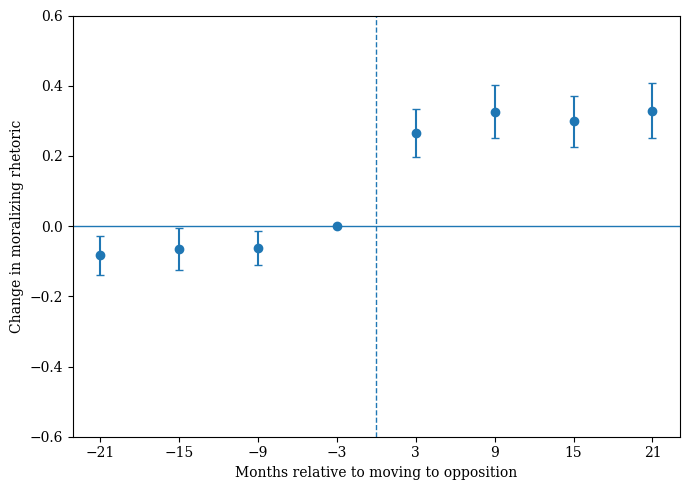

In [307]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    gov_opp["event_time"],
    gov_opp["coef"],
    yerr=1.96 * gov_opp["se"],
    fmt="o",
    capsize=3
)

ax.axhline(0, linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_xlabel("Months relative to moving to opposition")
ax.set_ylabel("Change in moralizing rhetoric")
#ax.set_title("Government → Opposition")

ax.set_xticks(
    [-21, -15, -9, -3, 3, 9, 15, 21]
)
ax.set_ylim(-0.6, 0.6)

plt.tight_layout()
plt.savefig(FIG_DIR / "gov-opp.jpg")
plt.show()

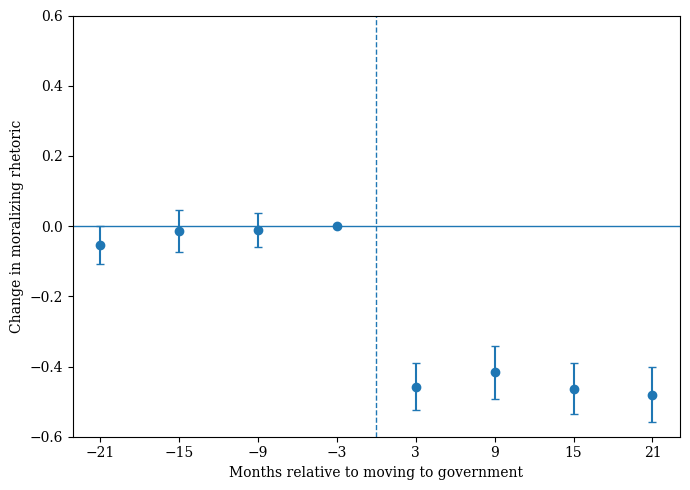

In [308]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    opp_gov["event_time"],
    opp_gov["coef"],
    yerr=1.96 * gov_opp["se"],
    fmt="o",
    capsize=3
)

ax.axhline(0, linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_xlabel("Months relative to moving to government")
ax.set_ylabel("Change in moralizing rhetoric")
#ax.set_title("Government → Opposition")

ax.set_xticks(
    [-21, -15, -9, -3, 3, 9, 15, 21]
)
ax.set_ylim(-0.6, 0.6)
plt.tight_layout()
out_path = FIG_DIR/ "opp-gov.jpg"
plt.savefig(out_path)
plt.show()

# MP-level

In [309]:
# prepare dataset
df_reg = df.copy()
df_reg['year_month'] = df_reg['date'].dt.to_period('M')
df_reg = (
    df_reg[['person_id', 'party_name_norm', 'moral_rating', 'year_month', 'gov_status']]
    .groupby(['person_id', 'year_month'], as_index=False)
        .agg(
            moral_rating=('moral_rating', 'mean'),
            party=('party_name_norm', 'first'),
            gov_status=('gov_status', 'first')
            )
)

In [310]:
election_periods = election_dates.to_period('M')

def months_to_next_election(date):
    if pd.isna(date):
        return np.nan

    date = pd.Period(date, freq='M')
    future = election_periods[election_periods >= date]

    if len(future) == 0:
        return np.nan

    next_election = future.min()

    return (
        (next_election.year - date.year) * 12
        + (next_election.month - date.month)
    )

In [311]:
df_reg["months_to_next_election"] = df_reg["year_month"].apply(months_to_next_election)

# Log months to election instead of days when we aggregate
df_reg["log_months_to_election"] = np.log(df_reg["months_to_next_election"] + 1)

# election terms

df_reg['election_term'] = (
    election_periods
        .searchsorted(df_reg['year_month'], side='right')
        - 1
)

In [312]:
print(df_reg[df_reg['election_term'] == 8].head())

                    person_id year_month  moral_rating        party  \
463  i-26JwMpJPh7ufEnA9hhtP9j    2022-12      1.750000  Moderaterna   
464  i-26JwMpJPh7ufEnA9hhtP9j    2023-01      1.900000  Moderaterna   
465  i-26JwMpJPh7ufEnA9hhtP9j    2023-02      2.500000  Moderaterna   
466  i-26JwMpJPh7ufEnA9hhtP9j    2023-04      2.666667  Moderaterna   
467  i-26JwMpJPh7ufEnA9hhtP9j    2023-05      2.888889  Moderaterna   

     gov_status  months_to_next_election  log_months_to_election  \
463           1                       45                3.828641   
464           1                       44                3.806662   
465           1                       43                3.784190   
466           1                       41                3.737670   
467           1                       40                3.713572   

     election_term  
463              8  
464              8  
465              8  
466              8  
467              8  


In [313]:


from stargazer.stargazer import Stargazer
import statsmodels.formula.api as smf

df_reg_ = df_reg
term_dummies = pd.get_dummies(df_reg_['election_term'], dtype=int)
# -------------------------
person_codes = df_reg_["person_id"].astype("category").cat.codes
month_codes = df_reg_["year_month"].astype("category").cat.codes
groups = np.column_stack((person_codes, month_codes))


df_reg_['election_term'] = df_reg_["election_term"].astype("category").cat.codes
X = df_reg_


mod1 = smf.ols(
    "moral_rating ~  gov_status + log_months_to_election + C(election_term)",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})

mod2 = smf.ols(
    "moral_rating ~  gov_status + log_months_to_election + C(election_term) + C(party, Treatment(reference='Socialdemokraterna'))",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})



mod3 =smf.ols(
    "moral_rating ~  gov_status * log_months_to_election + C(election_term) + C(party, Treatment(reference='Socialdemokraterna')) ",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})


mod4 = smf.ols(
    "moral_rating ~ C(party, Treatment(reference='Socialdemokraterna')) * log_months_to_election + gov_status * log_months_to_election + C(election_term)",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})

#print(mod4.summary())


stargazer = Stargazer([mod1, mod2, mod3])

latex_table = stargazer.render_latex()

print(latex_table)


\begin{table}[!htbp] \centering
\begin{tabular}{@{\extracolsep{5pt}}lccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{3}{c}{\textit{Dependent variable: moral_rating}} \
\cr \cline{2-4}
\\[-1.8ex] & (1) & (2) & (3) \\
\hline \\[-1.8ex]
 C(election_term)[T.1] & -0.097$^{**}$ & -0.130$^{***}$ & -0.131$^{***}$ \\
& (0.041) & (0.039) & (0.039) \\
 C(election_term)[T.2] & -0.037$^{}$ & -0.080$^{*}$ & -0.081$^{*}$ \\
& (0.042) & (0.042) & (0.042) \\
 C(election_term)[T.3] & 0.098$^{**}$ & 0.050$^{}$ & 0.049$^{}$ \\
& (0.043) & (0.042) & (0.042) \\
 C(election_term)[T.4] & 0.287$^{***}$ & 0.258$^{***}$ & 0.257$^{***}$ \\
& (0.043) & (0.042) & (0.042) \\
 C(election_term)[T.5] & 0.291$^{***}$ & 0.270$^{***}$ & 0.269$^{***}$ \\
& (0.043) & (0.041) & (0.041) \\
 C(election_term)[T.6] & 0.215$^{***}$ & 0.197$^{***}$ & 0.196$^{***}$ \\
& (0.044) & (0.043) & (0.043) \\
 C(election_term)[T.7] & 0.344$^{***}$ & 0.324$^{***}$ & 0.323$^{***}$ \\
& (0.044) & (0.043) & (0.043) \\
 C(election_term)[T

In [314]:
mod1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           moral_rating   R-squared:                       0.106
Model:                            OLS   Adj. R-squared:                  0.105
Method:                 Least Squares   F-statistic:                     67.44
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.28e-137
Time:                        13:20:21   Log-Likelihood:                -66309.
No. Observations:               59289   AIC:                         1.326e+05
Df Residuals:                   59278   BIC:                         1.327e+05
Df Model:                          10                                         
Covariance Type:              cluster                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  2.8542      0.042     68.436      0.000       2.772       2.936
C(election_term)[T.1]     -0.0972      0.041     -2.349      0.019      -0.178      -0.016
C(election_term)[T.2]     -0.0369      0.042     -0.873      0.383      -0.120       0.046
C(election_term)[T.3]      0.0977      0.043      2.290      0.022       0.014       0.181
C(election_term)[T.4]      0.2872      0.043      6.611      0.000       0.202       0.372
C(election_term)[T.5]      0.2910      0.043      6.761      0.000       0.207       0.375
C(election_term)[T.6]      0.2151      0.044      4.834      0.000       0.128       0.302
C(election_term)[T.7]      0.3437      0.044      7.741      0.000       0.257       0.431
C(election_term)[T.8]      0.3651      0.046      7.895      0.000       0.274       0.456
gov_status                -0.4184      0.019    -21.620      0.000      -0.456      -0.381
log_months_to_election    -0.0334      0.008     -4.061      0.000      -0.050      -0.017
==============================================================================
Omnibus:                      255.260   Durbin-Watson:                   1.456
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              207.120
Skew:                           0.073   Prob(JB):                     1.06e-45
Kurtosis:                       2.750   Cond. No.                         35.0
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (cluster)
"""

In [315]:
model = smf.ols(
    "moral_rating ~ C(party) + gov_status * log_months_to_election + C(election_term)",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})


In [316]:
print(X['party'].unique())

['Socialdemokraterna' 'Moderaterna' 'Liberalerna' 'Sverigedemokraterna'
 'Centerpartiet' 'Miljöpartiet' 'Vänsterpartiet' 'Kristdemokraterna'
 'Ny demokrati']


In [317]:
print(X['election_term'].unique())

[0 1 2 3 4 5 6 7 8]


In [318]:
X.columns

Index(['person_id', 'year_month', 'moral_rating', 'party', 'gov_status',
       'months_to_next_election', 'log_months_to_election', 'election_term'],
      dtype='object')

In [319]:
mod6 = smf.ols(
    "moral_rating ~ log_months_to_election + gov_status + C(party, Treatment(reference='Socialdemokraterna')) + C(election_term)",
    data=X
).fit(cov_type="cluster", cov_kwds={"groups": groups})

print(mod6.summary())


                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.134
Method:                 Least Squares   F-statistic:                     55.22
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.20e-87
Time:                        13:20:22   Log-Likelihood:                -65336.
No. Observations:               59289   AIC:                         1.307e+05
Df Residuals:                   59270   BIC:                         1.309e+05
Df Model:                          18                                         
Covariance Type:              cluster                                         
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------

In [320]:
mod7 = smf.ols(
    "moral_rating ~ gov_status + C(party, Treatment(reference='Socialdemokraterna'))*log_months_to_election + C(election_term)",
    data=X
).fit(cov_type="cluster", cov_kwds={"groups": groups})

print(mod7.summary())


                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.135
Method:                 Least Squares   F-statistic:                     40.81
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.09e-86
Time:                        13:20:22   Log-Likelihood:                -65318.
No. Observations:               59289   AIC:                         1.307e+05
Df Residuals:                   59262   BIC:                         1.309e+05
Df Model:                          26                                         
Covariance Type:              cluster                                         
                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------

In [321]:
stargazer = Stargazer([mod5, mod6, mod7])

latex_table = stargazer.render_latex()

print(latex_table)


\begin{table}[!htbp] \centering
\begin{tabular}{@{\extracolsep{5pt}}lccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{3}{c}{\textit{Dependent variable: moral_rating}} \
\cr \cline{2-4}
\\[-1.8ex] & (1) & (2) & (3) \\
\hline \\[-1.8ex]
 C(election_term)[T.1] & -0.101$^{***}$ & -0.130$^{***}$ & -0.130$^{***}$ \\
& (0.038) & (0.039) & (0.039) \\
 C(election_term)[T.2] & -0.053$^{}$ & -0.080$^{*}$ & -0.080$^{*}$ \\
& (0.041) & (0.042) & (0.042) \\
 C(election_term)[T.3] & 0.103$^{**}$ & 0.050$^{}$ & 0.050$^{}$ \\
& (0.040) & (0.042) & (0.042) \\
 C(election_term)[T.4] & 0.298$^{***}$ & 0.258$^{***}$ & 0.258$^{***}$ \\
& (0.040) & (0.042) & (0.042) \\
 C(election_term)[T.5] & 0.310$^{***}$ & 0.270$^{***}$ & 0.270$^{***}$ \\
& (0.042) & (0.041) & (0.041) \\
 C(election_term)[T.6] & 0.226$^{***}$ & 0.197$^{***}$ & 0.197$^{***}$ \\
& (0.043) & (0.043) & (0.043) \\
 C(election_term)[T.7] & 0.326$^{***}$ & 0.324$^{***}$ & 0.324$^{***}$ \\
& (0.041) & (0.043) & (0.043) \\
 C(election_term)[

In [322]:
import numpy as np
import pandas as pd

baseline = "Socialdemokraterna"
parties = X["party"].unique()

ame_results = []

for p in parties:
    if p == baseline:
        continue
    
    # copy data
    data_copy = X.copy()
    
    # predicted values if everyone were party p
    data_copy["party"] = p
    pred_p = mod6.predict(data_copy)
    
    # predicted values if everyone were baseline
    data_copy["party"] = baseline
    pred_base = mod6.predict(data_copy)
    
    ame = np.mean(pred_p - pred_base)
    
    ame_results.append({
        "party": p,
        "AME": ame
    })

ame_df = pd.DataFrame(ame_results).sort_values("AME")


In [323]:
ame_df

,party,AME
7,Ny demokrati,-0.192384
0,Moderaterna,-0.167269
3,Centerpartiet,-0.096174
2,Sverigedemokraterna,-0.056336
6,Kristdemokraterna,0.072133
1,Liberalerna,0.083045
4,Miljöpartiet,0.172583
5,Vänsterpartiet,0.300686


In [324]:
X_term = X[X['election_term'] == 0]
raw_diff = X_term.groupby('party')['moral_rating'].mean() - X_term[X_term['party']=='Centerpartiet']['moral_rating'].mean()
print(raw_diff)

party
Centerpartiet         0.000000
Kristdemokraterna     0.285153
Liberalerna           0.224130
Moderaterna          -0.113025
Ny demokrati          0.227075
Socialdemokraterna    0.363413
Vänsterpartiet        0.567750
Name: moral_rating, dtype: float64


In [325]:
mod4 = smf.ols(
    "moral_rating ~  gov_status + C(party) + log_months_to_election + C(election_term)",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})
print(mod4.summary())

                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.134
Method:                 Least Squares   F-statistic:                     55.22
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.20e-87
Time:                        13:20:25   Log-Likelihood:                -65336.
No. Observations:               59289   AIC:                         1.307e+05
Df Residuals:                   59270   BIC:                         1.309e+05
Df Model:                          18                                         
Covariance Type:              cluster                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [326]:
X['party'] = X['party'].astype('category')
X['election_term'] = X['election_term'].astype('category').cat.codes
mod = smf.ols(
    "moral_rating ~  gov_status + C(party) + log_months_to_election + C(election_term)",
    data=X
).fit(cov_type="cluster",
    cov_kwds={"groups":groups})
print(mod4.summary())

#plot_predictions(mod4,condition={"party": X['party'].unique(), "gov_status" : 0})

                            OLS Regression Results                            
Dep. Variable:           moral_rating   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.134
Method:                 Least Squares   F-statistic:                     55.22
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.20e-87
Time:                        13:20:25   Log-Likelihood:                -65336.
No. Observations:               59289   AIC:                         1.307e+05
Df Residuals:                   59270   BIC:                         1.309e+05
Df Model:                          18                                         
Covariance Type:              cluster                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [327]:
X['party'].value_counts()

party
Socialdemokraterna     18163
Moderaterna            13184
Centerpartiet           5195
Vänsterpartiet          5179
Liberalerna             5160
Kristdemokraterna       5046
Miljöpartiet            4017
Sverigedemokraterna     2914
Ny demokrati             431
Name: count, dtype: int64

In [328]:
df_plot = df.copy()
print(df_plot)
df_plot["date"] = pd.to_datetime(df_plot["date"], errors="coerce")
df_plot = df_plot.dropna(subset=["date", "moral_rating"])


def nearest_election(date, elections):
    deltas = elections - date          # TimedeltaIndex
    idx = np.argmin(np.abs(deltas))    # numpy handles abs()
    return elections[idx]

df_plot["election_date"] = df_plot["date"].apply(
    lambda d: nearest_election(d, election_dates)
)

                       person_id       date                  party_id  \
0       i-4CwyNH4xXJhZj5wdBAzmSY 1996-02-23  i-VS8ddgxigwL5TceKtXGApS   
1       i-F8qdE2eedz12PwFanq3ahv 1996-02-23  i-F6Stwe8wVnSPa3BbgusszQ   
2       i-4CwyNH4xXJhZj5wdBAzmSY 1996-02-23  i-VS8ddgxigwL5TceKtXGApS   
3       i-F8qdE2eedz12PwFanq3ahv 1996-02-23  i-F6Stwe8wVnSPa3BbgusszQ   
4       i-4CwyNH4xXJhZj5wdBAzmSY 1996-02-23  i-VS8ddgxigwL5TceKtXGApS   
...                          ...        ...                       ...   
427008  i-XawAMXosHR6z4JL22muW4x 2000-04-05  i-VS8ddgxigwL5TceKtXGApS   
427009  i-UtrdG3TunFF2Q5dXbR45yN 2000-04-05  i-BRRSButj7zSqB1u7zD6hod   
427010  i-XawAMXosHR6z4JL22muW4x 2000-04-05  i-VS8ddgxigwL5TceKtXGApS   
427011  i-DKsVYU73WDtSTFEeLoboVx 2000-04-05  i-F6Stwe8wVnSPa3BbgusszQ   
427013  i-GN2jVbnWZ4paSMz4G7gSPo 2000-04-05  i-VS8ddgxigwL5TceKtXGApS   

                      party_name  moral_rating new_custom_id  \
0             Socialdemokraterna             2         row_

In [329]:
df_plot["event_month"] = (
    (df_plot["date"].dt.year - df_plot["election_date"].dt.year) * 12 +
    (df_plot["date"].dt.month - df_plot["election_date"].dt.month)
)
WINDOW = 88  # ±24 months
df_plot = df_plot[df_plot["event_month"].between(-WINDOW, WINDOW)]

In [330]:
df_plot["event_week"] = (df_plot["date"] - df_plot["election_date"]).dt.days // 7

WINDOW =  44# number of weeks before/after election
df_plot = df_plot[df_plot["event_week"].between(-WINDOW, WINDOW-20)]

In [331]:
# aggregate across all the elections

summary = (
    df_plot
    .groupby(["event_week"])["moral_rating"]
    .mean()
    .reset_index()
    .sort_values("event_week")
)


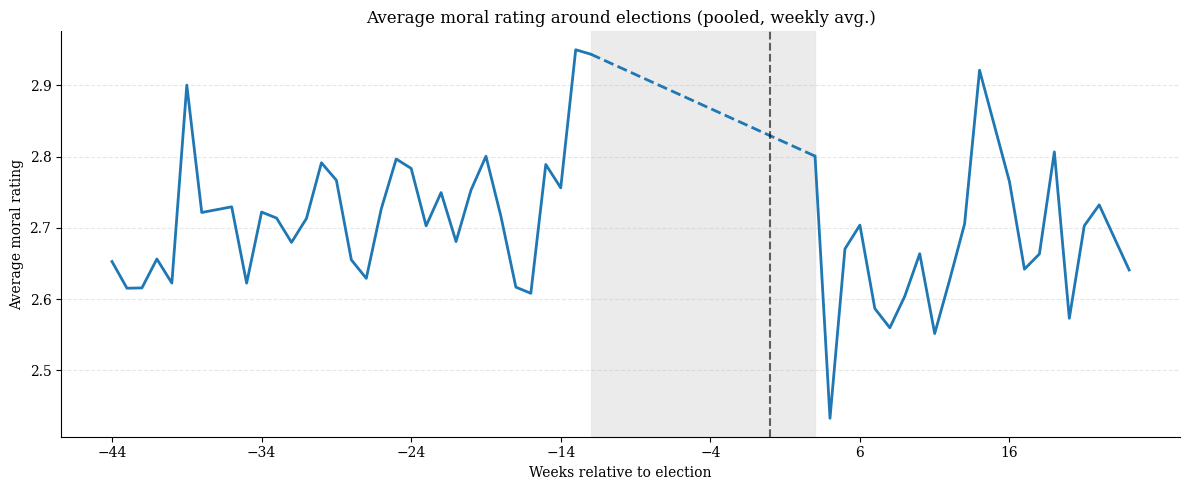

In [332]:
fig, ax = plt.subplots(figsize=(12, 5))

# Grey election window
ax.axvspan(-12, 3, color="0.9", alpha=0.8, zorder=0)


data = summary.sort_values("event_week")

pre = data[data["event_week"] < -11]
post = data[data["event_week"] >= 3]

color = None

# solid pre
if not pre.empty:
    line, = ax.plot(
        pre["event_week"],
        pre["moral_rating"],
        lw=2,
        #label=gov_label
    )
    color = line.get_color()

# solid post
if not post.empty:
    ax.plot(
        post["event_week"],
        post["moral_rating"],
        lw=2,
        color=color
    )

# dashed bridge
if not pre.empty and not post.empty:
    ax.plot(
        [pre["event_week"].iloc[-1], post["event_week"].iloc[0]],
        [pre["moral_rating"].iloc[-1], post["moral_rating"].iloc[0]],
        lw=2,
        linestyle="--",
        color=color
    )

# Election reference line
ax.axvline(0, linestyle="--", color="black", alpha=0.6)
plt.xticks(range(int(summary["event_week"].min()), 
                 int(summary["event_week"].max()), 10))
ax.set_title("Average moral rating around elections (pooled, weekly avg.)")
ax.set_xlabel("Weeks relative to election")
ax.set_ylabel("Average moral rating")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
#ax.legend()

plt.tight_layout()
plt.show()



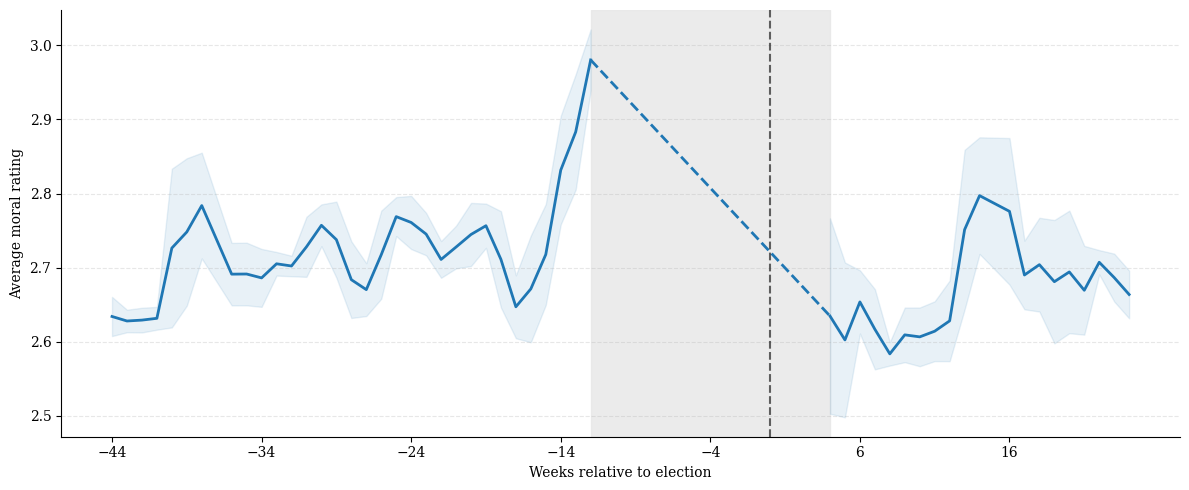

In [333]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))

# Grey election window
ax.axvspan(-12, 4, color="0.9", alpha=0.8, zorder=0)

window_size = 3  # rolling window in weeks


data = data.sort_values("event_week").copy()

# Compute rolling mean
data["moral_rating_smooth"] = data["moral_rating"].rolling(
    window=window_size, center=True, min_periods=1
).mean()

# Compute rolling standard error
data["se"] = data["moral_rating"].rolling(
    window=window_size, center=True, min_periods=1
).sem()  # pandas' sem = std / sqrt(n)

pre = data[data["event_week"] < -11]
post = data[data["event_week"] >= 4]

color = None

# solid pre with shaded SE
if not pre.empty:
    line, = ax.plot(
        pre["event_week"],
        pre["moral_rating_smooth"],
        lw=2,
       # label=gov_label
    )
    color = line.get_color()
    ax.fill_between(
        pre["event_week"],
        pre["moral_rating_smooth"] - pre["se"],
        pre["moral_rating_smooth"] + pre["se"],
        color=color,
        alpha=0.1
    )

# solid post with shaded SE
if not post.empty:
    ax.plot(
        post["event_week"],
        post["moral_rating_smooth"],
        lw=2,
        color=color
    )
    ax.fill_between(
        post["event_week"],
        post["moral_rating_smooth"] - post["se"],
        post["moral_rating_smooth"] + post["se"],
        color=color,
        alpha=0.1
    )

# dashed bridge
if not pre.empty and not post.empty:
    ax.plot(
        [pre["event_week"].iloc[-1], post["event_week"].iloc[0]],
        [pre["moral_rating_smooth"].iloc[-1], post["moral_rating_smooth"].iloc[0]],
        lw=2,
        linestyle="--",
        color=color
    )

# Election reference line
ax.axvline(0, linestyle="--", color="black", alpha=0.6)

plt.xticks(range(int(summary["event_week"].min()), 
                 int(summary["event_week"].max()), 10))
#ax.set_title("Average Moral Rating Around Elections (Weekly Averages, Pooled; 3-Week Rolling Mean)")
ax.set_xlabel("Weeks relative to election")
ax.set_ylabel("Average moral rating")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
#ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "pooled.jpg")
plt.show()
